# **Capacity Factors Compared to IRENA**

Extracted capacity factors of PV and onshore wind compared to IRENA, only for 2010–2025 (the years with IRENA reference data), under different assumptions and for regions and single countries.

IRENA lines: capacity-weighted average of newly commissioned projects (dashed, *IRENA Renewable Power Generation Costs in 2024*) and of the existing fleet (dotted, IRENASTAT generation / capacity).

In [1]:
import sys
import os
import pandas as pd
sys.path.append(os.path.abspath('..'))

from quinex_application.postprocessing.data_loading import (
    load_property_data, filter_by_unit_uri, load_reference_series,
)
from quinex_application.postprocessing.data_processing import assign_country, fill_author_countries
from quinex_application.postprocessing.irena_reference import (
    write_country_capacity_factor_series, write_region_capacity_factor_series,
)
from quinex_application.postprocessing.country_codes import REGION_COUNTRIES, COUNTRY_TO_REGION
from quinex_application.visualisation.temporal_visualisation import TemporalVisualisation
from quinex_application.visualisation.plot_utils import show_figure

# True: plots use only records from full-text publications
FULL_TEXT_ONLY = False
CORPUS = "full_text" if FULL_TEXT_ONLY else "all"  # suffix for saved files

TECHNOLOGIES_PATH = "../data/visualisation_files/df_technologies.parquet"
# Older publication metadata: author countries of publications missing in the OpenAlex file
METADATA_PATH = "../data/quinex/df_quinex_metadata.parquet"
IRENA_DIR = "../data/visualisation_files/irena"
UNIT = "http://qudt.org/vocab/unit/"

TECHNOLOGIES = ['PV', 'Onshore Wind']
MIN_CF = 15  # [%] onshore wind values below are removed in panels b-j
# False: country of a value only from the author countries (spatial scope ignored)
USE_SPATIAL_SCOPE = True
COUNTRIES = {"USA": "United States", "GBR": "United Kingdom", "CAN": "Canada", "CHN": "China", "IND": "India"}

visualisation = TemporalVisualisation()

## **Preprocessing**

### **Extracted Values**

Country of a value: spatial scope, as fallback the countries of the authors (`USE_SPATIAL_SCOPE = False`: only the countries of the authors). Values of publications with authors from several countries count for each of these countries; in a region a value counts once. Author countries missing in the OpenAlex file are taken from `METADATA_PATH`.

In [2]:
cap_factor_raw = load_property_data(TECHNOLOGIES_PATH, "Capacity Factor")
percent = filter_by_unit_uri(cap_factor_raw, UNIT + "PERCENT")
unitless = filter_by_unit_uri(cap_factor_raw, UNIT + "UNITLESS")
unitless = unitless[unitless['value_normalized'].between(0, 1)]  # fractions, scaled to percent
unitless['value_normalized'] = unitless['value_normalized'] * 100

cap_factor = pd.concat([percent, unitless], ignore_index=True)
cap_factor['entity_mapping'] = cap_factor['entity_mapping'].replace({'Wind': 'Onshore Wind'})
cap_factor = cap_factor[cap_factor["entity_mapping"].isin(TECHNOLOGIES)]
cap_factor = fill_author_countries(cap_factor, METADATA_PATH)
onshore_above_min = cap_factor[
    (cap_factor["entity_mapping"] == "Onshore Wind") & (cap_factor["value_normalized"] >= MIN_CF)
]

# Panels c-j: onshore wind values below MIN_CF removed, PV kept
plausible_cf = cap_factor[
    (cap_factor["entity_mapping"] != "Onshore Wind") | (cap_factor["value_normalized"] >= MIN_CF)
]
by_country = assign_country(plausible_cf, all_author_countries=True, use_spatial_scope=USE_SPATIAL_SCOPE).dropna(subset=["country"])
by_country["region"] = by_country["country"].map(COUNTRY_TO_REGION)
by_region = (
    by_country.dropna(subset=["region"]).reset_index()
    .drop_duplicates(["index", "region"]).set_index("index")
)

### **IRENA Reference Data**

Written from the two IRENA files to `irena/new_projects/` and `irena/existing_fleet/` (one CSV per line):

- Existing fleet: IRENASTAT, per country and region (implausible country values are left out, see `PLAUSIBLE_FLEET_CAPACITY_FACTORS`).
- New projects: onshore wind per country (Datafile, Fig. 2.11, 2.12); regions combine these weighted by the capacity added per year (North America: Canada, Mexico, USA, 97–100 % of the capacity added; Europe 86–98 %). PV per country only for China, USA, India, Brazil and Germany, 2022–2024 (Datafile, Fig. 1.14).

In [3]:
IRENA_DATAFILE = f"{IRENA_DIR}/IRENA-Datafile-RenPwrGenCosts-in-2024.xlsx"
IRENA_FLEET = f"{IRENA_DIR}/IRENAStat_Fleet.xlsx"
SERIES_DIRS = [f"{IRENA_DIR}/new_projects", f"{IRENA_DIR}/existing_fleet"]

write_country_capacity_factor_series(
    IRENA_DATAFILE, IRENA_FLEET, f"{IRENA_DIR}/existing_fleet/capacity_factor_countries",
    f"{IRENA_DIR}/new_projects/capacity_factor_countries", by_country["country"].unique(),
)
write_region_capacity_factor_series(
    IRENA_DATAFILE, IRENA_FLEET, f"{IRENA_DIR}/existing_fleet/capacity_factor_regions",
    f"{IRENA_DIR}/new_projects/capacity_factor_regions", REGION_COUNTRIES,
)
world_reference, country_reference, region_reference = (
    load_reference_series([f"{d}/{folder}" for d in SERIES_DIRS])
    for folder in ["capacity_factor", "capacity_factor_countries", "capacity_factor_regions"]
)

## **Capacity Factors of PV and Onshore Wind**

- **a** all values (values without temporal scope get the publication year)
- **b** onshore wind values below `MIN_CF` removed (for PV such values are plausible)
- **c** only values with a temporal scope year (no publication year fallback), onshore wind values below `MIN_CF` removed
- **d, e** regions, compared to the IRENA values of the region
- **f–j** single countries, compared to the IRENA values of the country (PV new projects only for China, USA and India, 2022–2024)

In panels c–j onshore wind values below `MIN_CF` are removed as in **b**; PV values are all kept.

Panels d–j have fewer values, so they need only 2 papers and 2 values per year (counted over both technologies of a panel); years with fewer are left out. Offshore wind (too few values per region and country) and Japan (14 onshore wind, 13 PV values) are left out.


=== Temporal Plot Generation Summary ===
[1] a  All values | IQR removed: 52 values (before=1402, after=1350)
    Contributing studies (DOI): 641 unique DOI(s) (full text: 623, abstract only: 18)
[2] b  Onshore wind ≥ 15 % | IQR removed: 15 values (before=647, after=632)
    Contributing studies (DOI): 377 unique DOI(s) (full text: 367, abstract only: 10)
[3] c  Temporal scope only | IQR removed: 11 values (before=173, after=162)
    No publication year fallback: removed 1130 values without temporal scope
    Contributing studies (DOI): 99 unique DOI(s) (full text: 98, abstract only: 1)
[4] d  Europe | IQR removed: 29 values (before=519, after=490)
    Contributing studies (DOI): 263 unique DOI(s) (full text: 262, abstract only: 1)
[5] e  North America | IQR removed: 11 values (before=238, after=227)
    Contributing studies (DOI): 118 unique DOI(s) (full text: 117, abstract only: 1)
[6] f  United States | IQR removed: 9 values (before=179, after=170)
    Contributing studies (DOI): 8

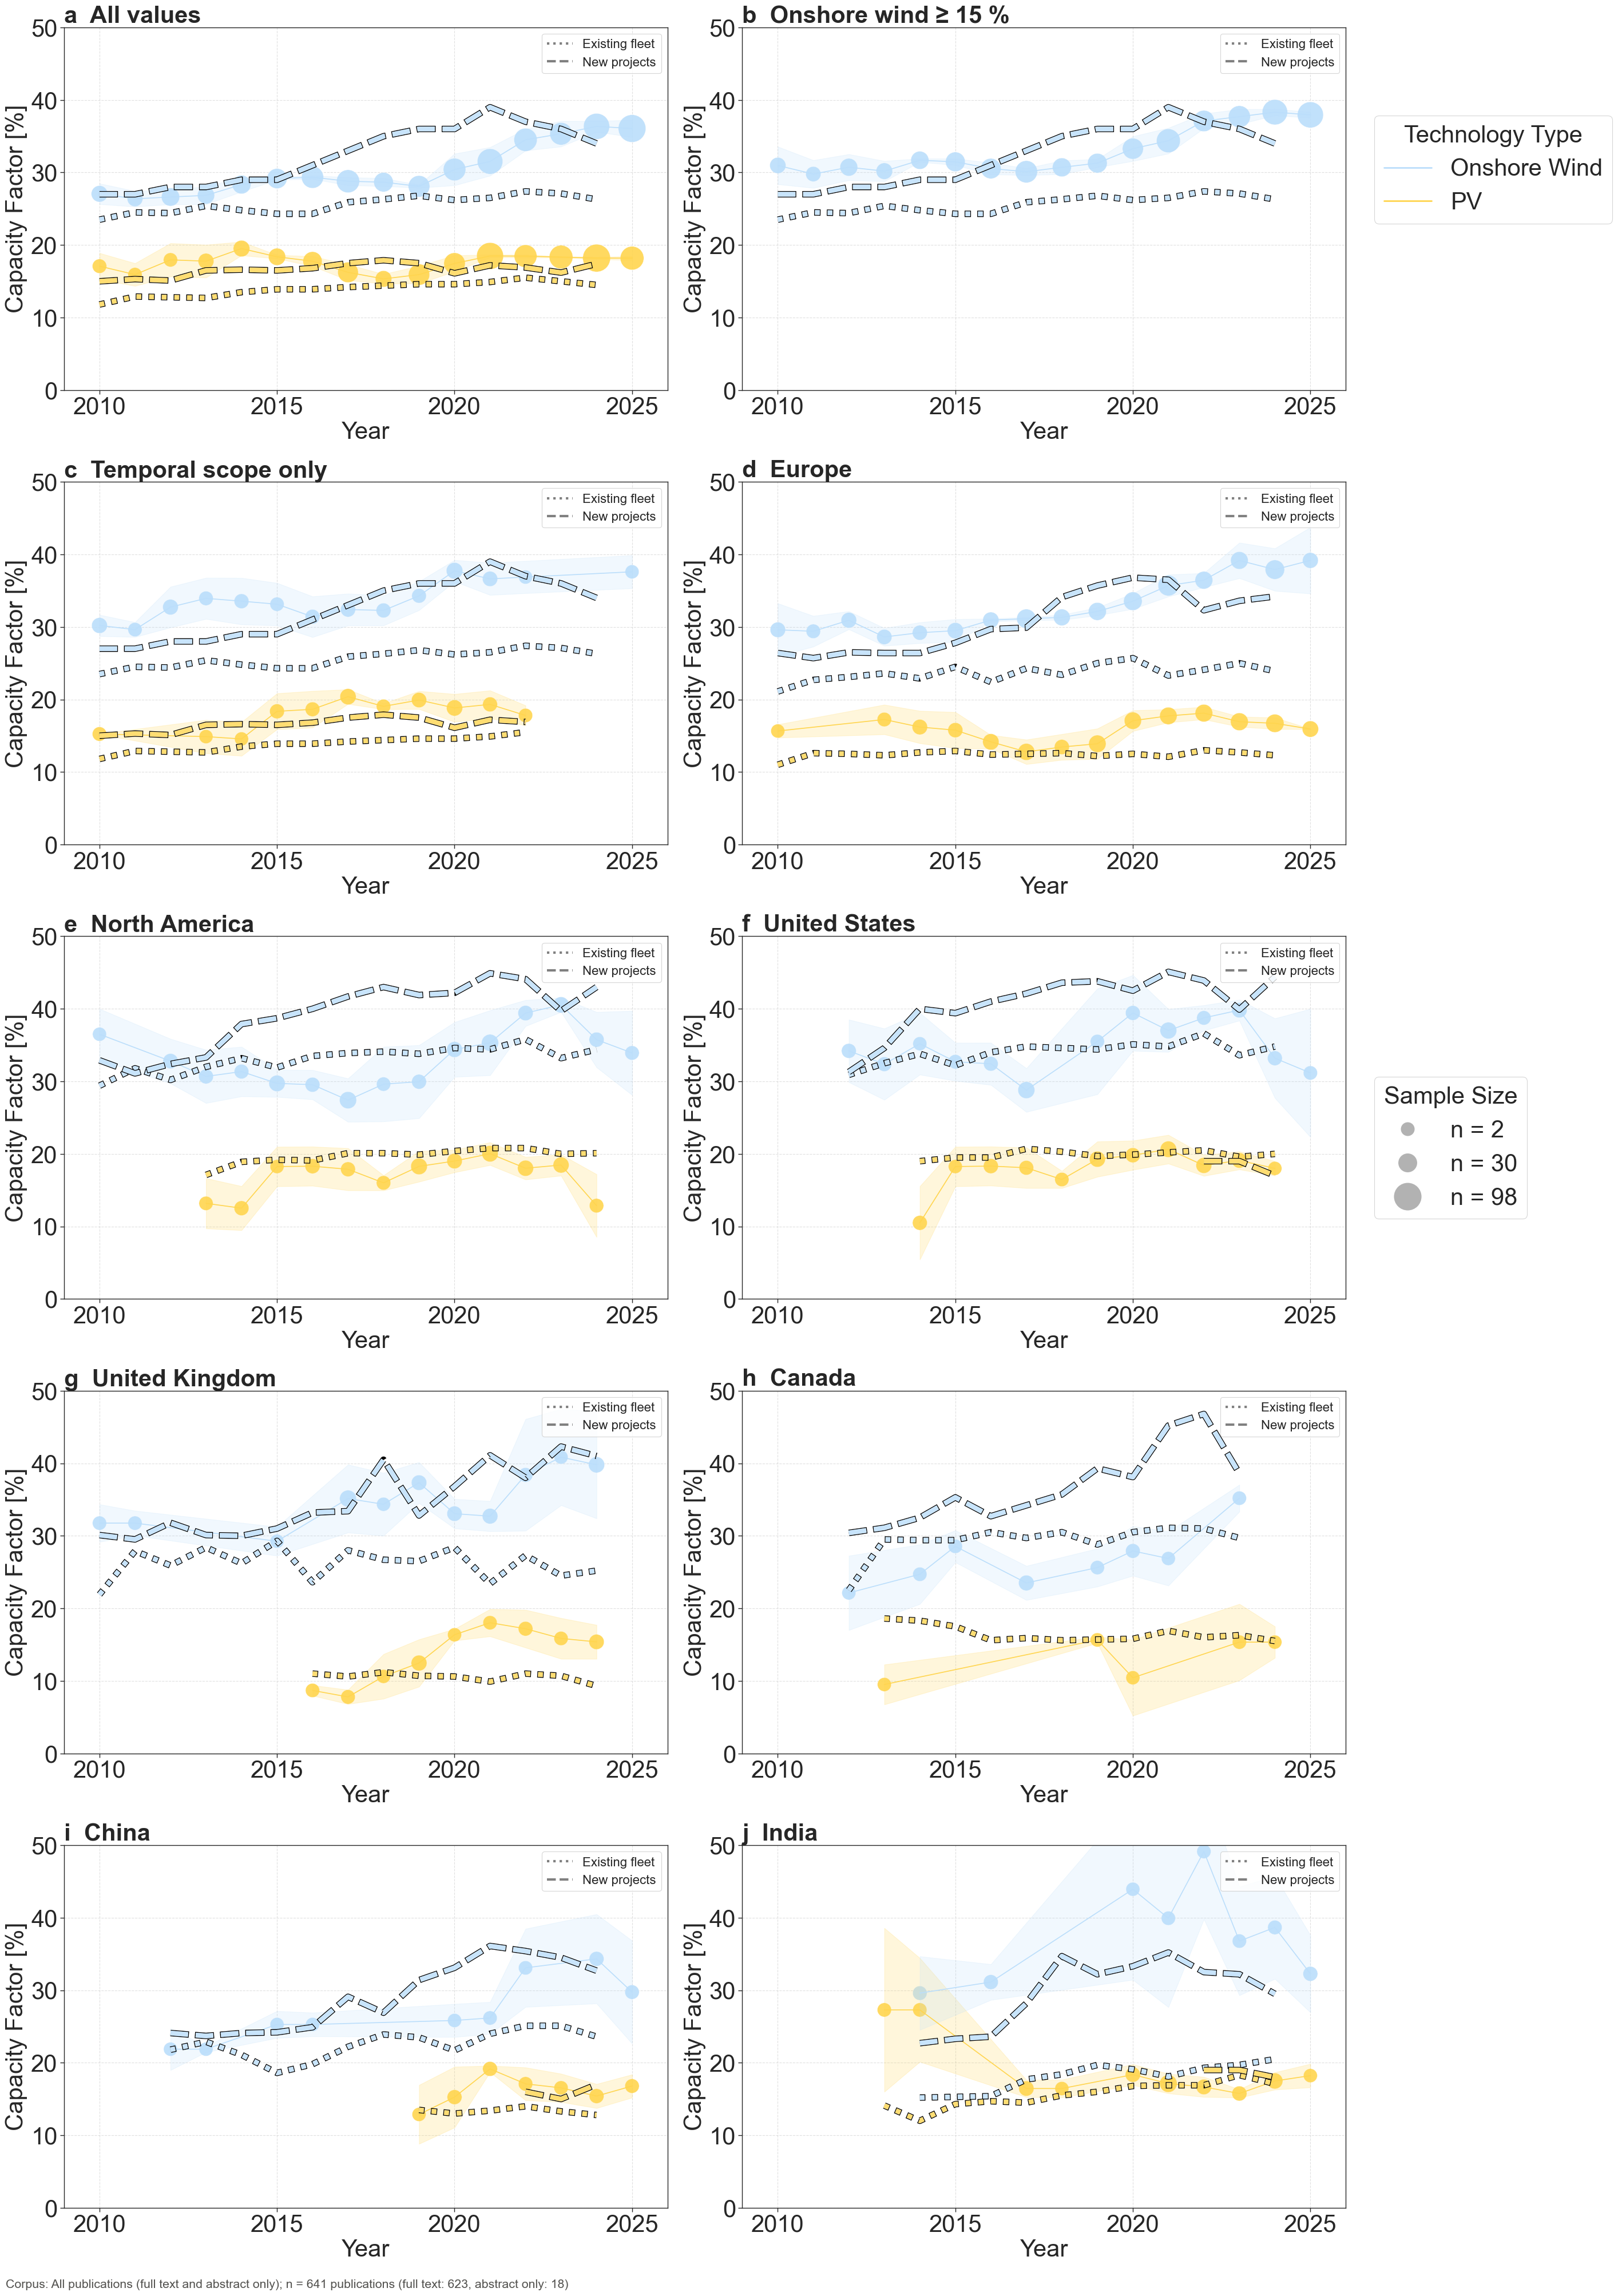

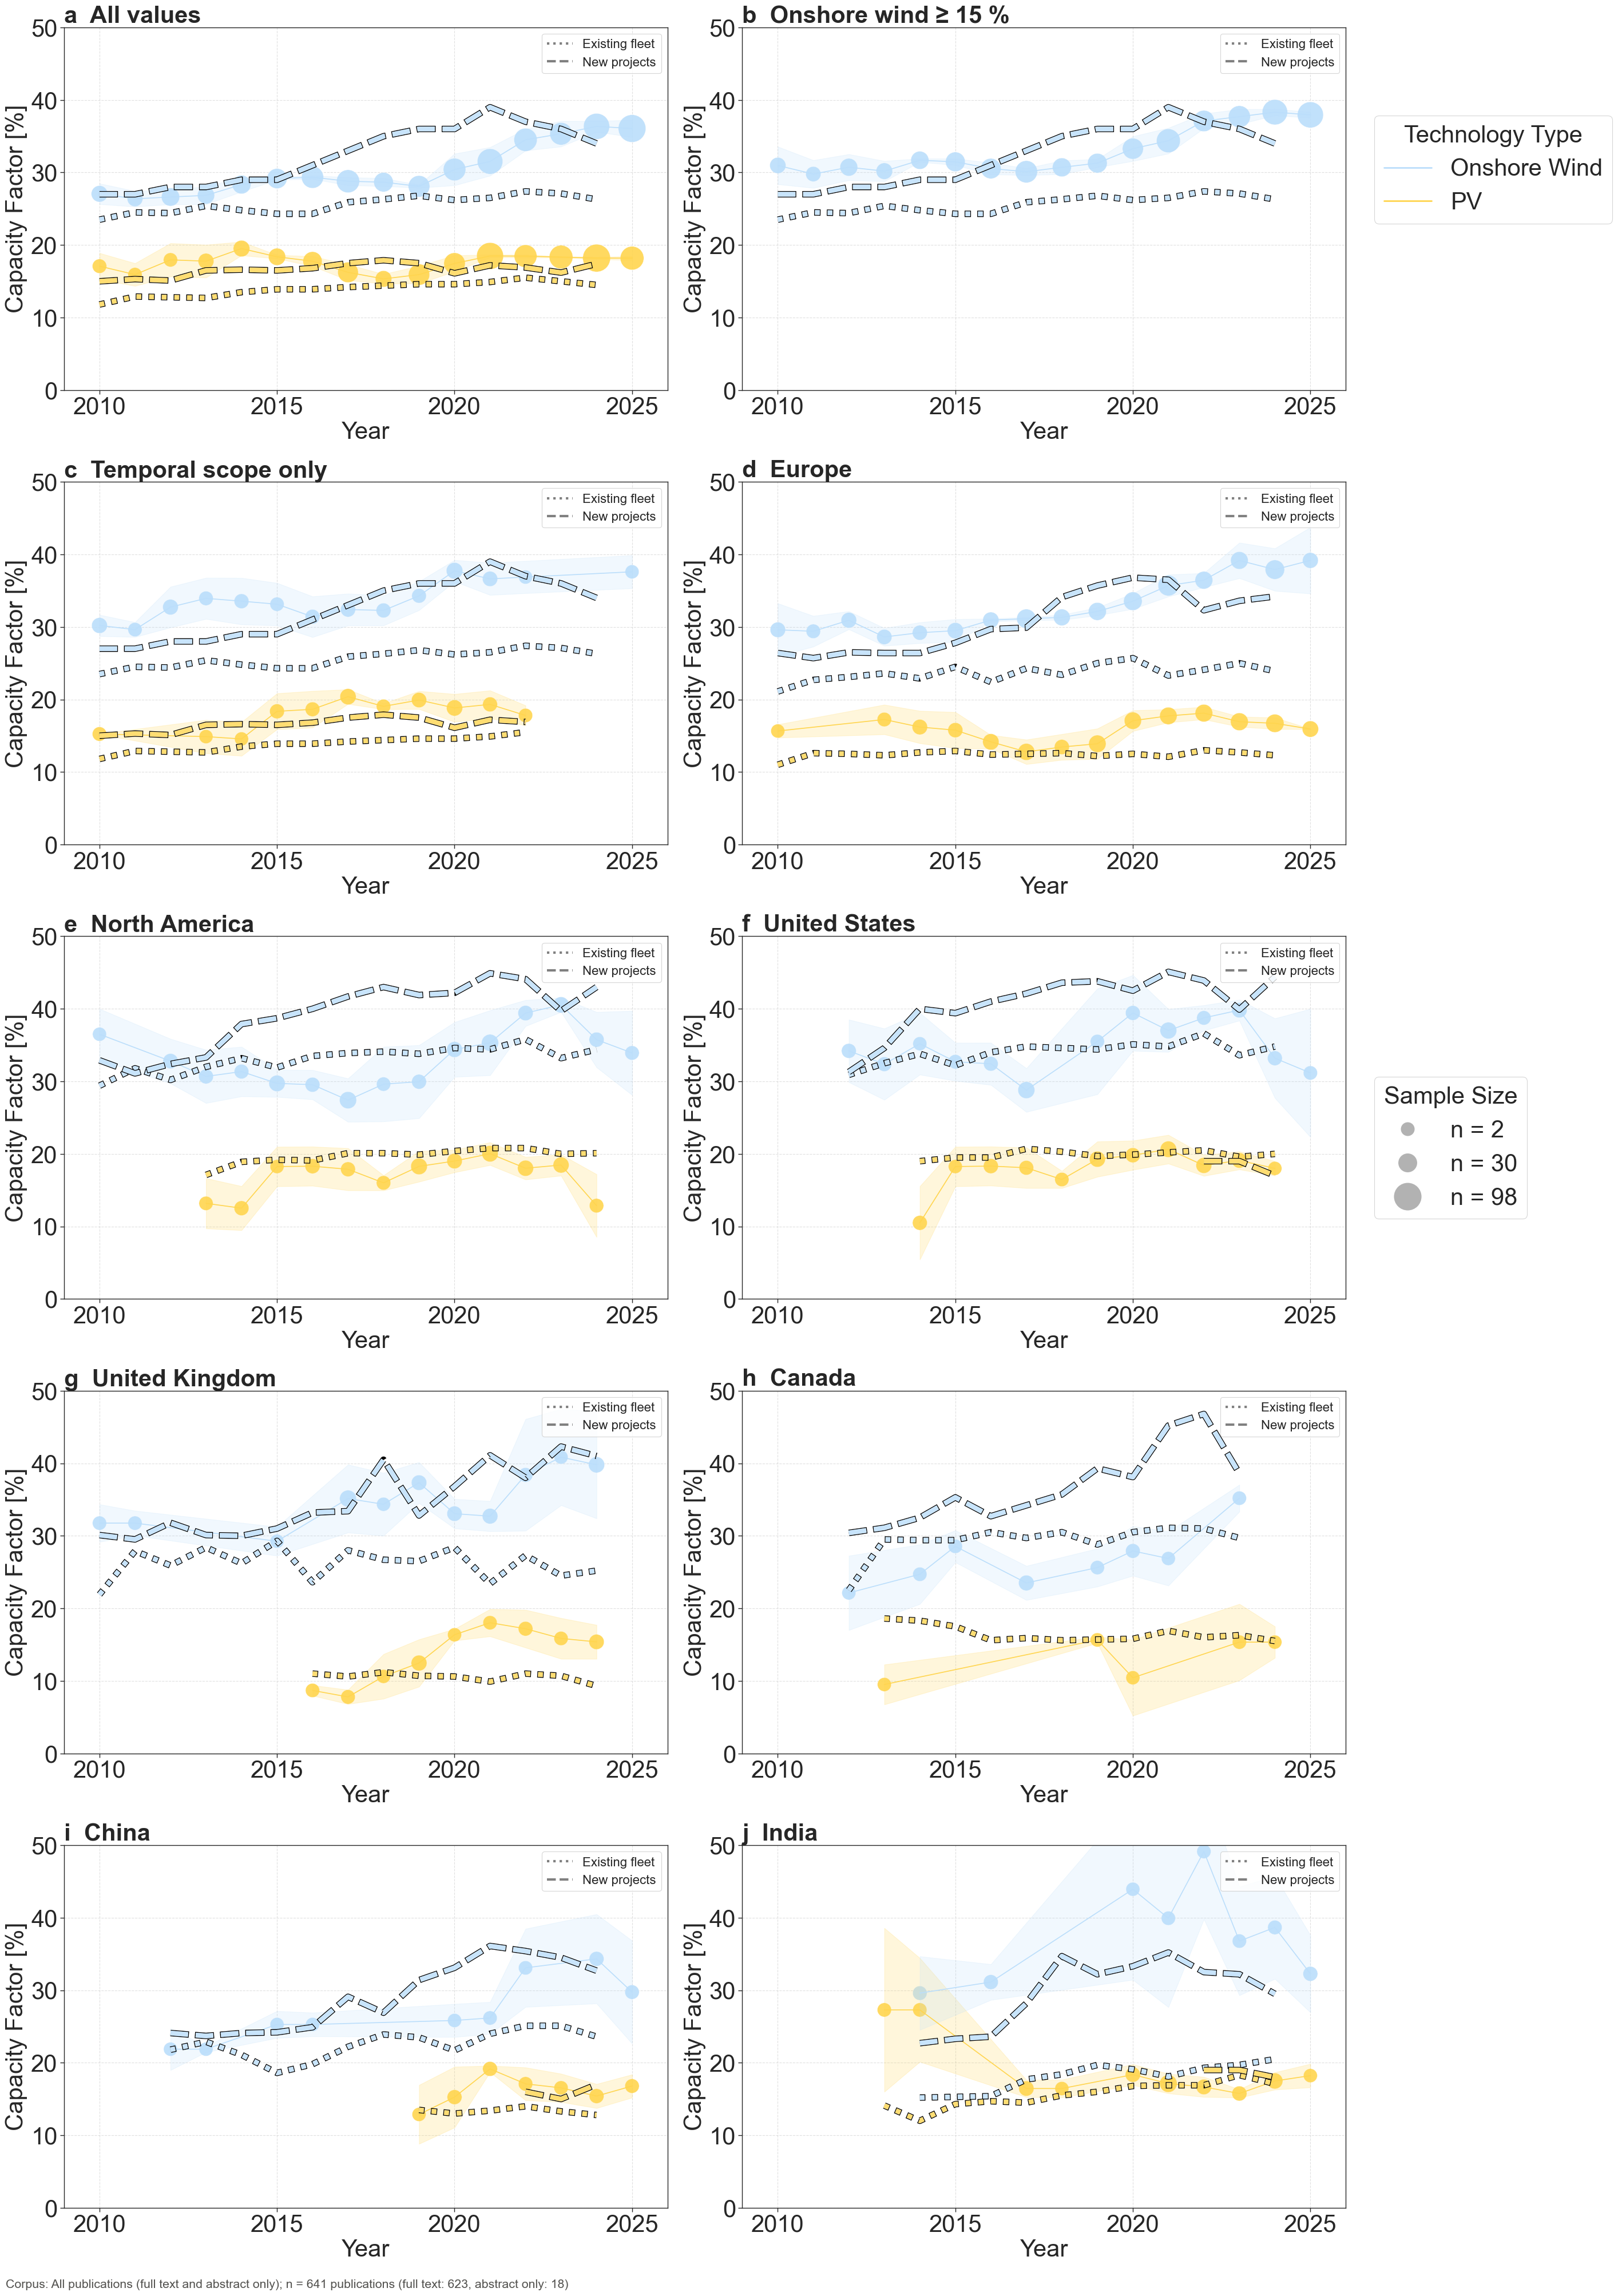

In [6]:
PANEL = {
    'entity_col': 'entity_mapping', 'value_col': 'value_normalized', 'ylabel': 'Capacity Factor [%]',
    'year_range': (2009, 2026), 'y_range': (0, 50),
}
FEW_VALUES = {**PANEL, 'min_papers_per_year': 2, 'min_datapoints_per_year': 2}

data = [
    {**PANEL, 'df': cap_factor, 'title': 'a  All values', 'additional_data': world_reference},
    {**PANEL, 'df': onshore_above_min, 'title': f'b  Onshore wind ≥ {MIN_CF} %', 'additional_data': world_reference},
    {**PANEL, 'df': plausible_cf, 'title': 'c  Temporal scope only', 'additional_data': world_reference,
     'publication_year_fallback': False},
]
data += [
    {**FEW_VALUES, 'df': by_region[by_region["region"] == region], 'title': f'{letter}  {region}',
     'additional_data': region_reference[region_reference["region"] == region]}
    for letter, region in zip("de", ["Europe", "North America"])
]
data += [
    {**FEW_VALUES, 'df': by_country[by_country["country"] == iso3], 'title': f'{letter}  {name}',
     'additional_data': country_reference[country_reference["country"] == iso3]}
    for letter, (iso3, name) in zip("fghij", COUNTRIES.items())
]

fig, tables = visualisation.plot_multiple_properties_over_time(
    data_list=data,
    legend_title='Technology Type',
    color_dict=visualisation.entity_colors,
    figsize=(24, 40),
    legend_position=(1.0, 0.95),
    legend_size_position=(1.0, 0.53),
    central_tendency="moving average",
    error_type="se",
    error_display="shade",
    font_size=30,
    point_size_range=(300, 1200),
    min_papers_per_year=2,
    min_datapoints_per_year=2,
    iqr_lower_quantile=0.25,
    iqr_upper_quantile=0.75,
    iqr_multiplier=3,
    full_text_only=FULL_TEXT_ONLY,
    data_year_range=(2010, 2025),  # years with IRENA reference data
)
show_figure(fig)
show_figure(fig, save_path=f"../data/figures/results/temporal/irena_cf_{CORPUS}.pdf")

## **Agreement with IRENA under Harmonisation Steps (Table)**

Onshore wind only, one row per panel a–i and two sensitivity subsets (full-text publications only; records citing an IRENA report excluded, both with onshore wind values below `MIN_CF` removed).

- **Records, Publications**: onshore wind records of the subset (panel c: only those with a temporal scope year)
- **Explicit year**: share of these records with a temporal scope year extracted by Quinex
- **MAE**: mean absolute difference between the 3-year moving average and the IRENA line over the years covered by both (`build_log_regression_metric_labels`)
- **Delay**: shift of the new projects series by 0 to `MAX_DELAY` years with the smallest RMSE to the moving average; the RMSE of every shift is listed to judge the minimum (a minimum at `MAX_DELAY` means the academic series does not reach the new projects level)

In [ ]:
import re
import numpy as np
import matplotlib.pyplot as plt
from quinex_application.postprocessing.data_processing import parse_temporal_scope, restrict_datasets_to_full_text
from quinex_application.visualisation.regression_metrics import build_log_regression_metric_labels

ONSHORE = 'Onshore Wind'
MAX_DELAY = 6  # [yr] largest shift of the new projects series tested for the delay
IRENA_CITATION = r"IRENA|International Renewable Energy Agency|Renewable Power Generation Costs"


def cites_irena(reference) -> bool:
    """True if the citation text or a cited title / venue of a record mentions IRENA."""
    if not isinstance(reference, dict):
        return False
    works = reference.get('normalized')
    parts = [reference.get('text')] + [
        part for work in (works if works is not None else []) for part in (work.get('title'), work.get('venue'))
    ]
    return re.search(IRENA_CITATION, ' '.join(p for p in parts if p), flags=re.IGNORECASE) is not None


def rmse_by_delay(academic: pd.Series, new_projects: pd.Series) -> pd.Series:
    """RMSE between the academic series and the new projects series shifted by 0 to MAX_DELAY years."""
    rmse = {}
    for delay in range(MAX_DELAY + 1):
        diff = (academic - new_projects.set_axis(new_projects.index + delay)).dropna()
        if len(diff):
            rmse[delay] = np.sqrt((diff ** 2).mean())
    return pd.Series(rmse, dtype=float)


irena_citing = onshore_above_min['reference'].apply(cites_irena)
print(f"Records citing IRENA (onshore wind ≥ {MIN_CF} %): {irena_citing.sum()} records from "
      f"{onshore_above_min.loc[irena_citing, 'DOI'].nunique()} publications")
for reference in onshore_above_min.loc[irena_citing, 'reference']:
    print("   ", reference['text'])

# Rows of the table: panels a-c and d-i of the figure and the two sensitivity subsets
subsets = {
    'All values (a)': data[0],
    f'Onshore wind ≥ {MIN_CF} % (b)': data[1],
    f'Temporal scope only, ≥ {MIN_CF} % (c)': data[2],
    f'Full-text publications only, ≥ {MIN_CF} %': restrict_datasets_to_full_text([data[1]])[0],
    f'IRENA-citing records excluded, ≥ {MIN_CF} %': {**data[1], 'df': onshore_above_min[~irena_citing]},
    **{f"{entry['title'][3:]} ({entry['title'][0]})": entry for entry in data[3:9]},
}
entries = [{**entry, 'title': label} for label, entry in subsets.items()]
if FULL_TEXT_ONLY:
    entries = restrict_datasets_to_full_text(entries)

# Aggregated series with the settings of the figure above
table_fig, series_tables = visualisation.plot_multiple_properties_over_time(
    data_list=entries, legend_title='Technology Type', color_dict=visualisation.entity_colors,
    central_tendency="moving average", error_type="se",
    min_papers_per_year=2, min_datapoints_per_year=2,
    iqr_lower_quantile=0.25, iqr_upper_quantile=0.75, iqr_multiplier=3,
    data_year_range=(2010, 2025), print_summary=False, corpus_note=False,
)
plt.close(table_fig)

rows = []
for entry in entries:
    records = entry['df'][entry['df']['entity_mapping'] == ONSHORE]
    explicit = parse_temporal_scope(records, 'temporal_scope', None)
    if entry.get('publication_year_fallback') is False:
        records = explicit

    agg_df = series_tables[entry['title']]
    labels = build_log_regression_metric_labels(agg_df, 'entity_mapping', additional_df=entry['additional_data'])
    mae = dict(re.findall(rf"^{ONSHORE}_(.+?): .*MAE=([\d.]+)", '\n'.join(labels), flags=re.MULTILINE))

    reference = entry['additional_data']
    new_projects = reference[(reference['entity'] == ONSHORE) & (reference['series'] == 'New projects')]
    academic = agg_df[agg_df['entity_mapping'] == ONSHORE].set_index('jahr')['value_central']
    rmse = rmse_by_delay(academic, new_projects.groupby('year')['value'].mean())

    rows.append({
        'Subset': entry['title'],
        'Records': len(records),
        'Publications': records['DOI'].nunique(),
        'Explicit year (%)': round(100 * len(explicit) / len(records), 1),
        'MAE new projects (pts)': mae.get('New projects'),
        'MAE existing fleet (pts)': mae.get('Existing fleet'),
        'Delay (yr)': rmse.idxmin() if len(rmse) else None,
        f'RMSE by delay 0-{MAX_DELAY} yr': ' / '.join(f"{value:.1f}" for value in rmse),
    })

harmonisation_table = pd.DataFrame(rows).set_index('Subset')
display(harmonisation_table)

all_onshore = parse_temporal_scope(cap_factor[cap_factor['entity_mapping'] == ONSHORE], 'temporal_scope', None)
print("Median difference publication year - temporal scope (onshore wind, explicit year): "
      f"{(all_onshore['publication_year'] - all_onshore['jahr']).median():.0f} years")